# ¿Rescata el muestreo por información la hipótesis del rango de apertura?

**BTCUSDT perpetuo (Binance USDⓈ-M) · barras de volumen, dólar y desequilibrio · 2022–2026**

## La pregunta

`Intraday_Momentum_OR_VWAP.ipynb` devolvió un nulo: la primera vela de **5 minutos** de la sesión
de contado de EE. UU. predice el cierre de la sesión el **49,8 %** de las veces sobre 1 225
sesiones. Una moneda al aire.

López de Prado (*AFML*, cap. 2) sostiene que eso puede ser un artefacto de **cómo se muestrearon
los datos**, no de la hipótesis: la información no llega de forma uniforme en tiempo de reloj, así
que las barras de tiempo sobremuestrean los tramos tranquilos e inframuestrean los activos, y
producen series con malas propiedades estadísticas. La afirmación que se pone a prueba aquí:

> **Muestrea por actividad en vez de por el reloj y la señal aparece.**

En concreto: que el signo y la posición respecto al VWAP de los primeros **5 000 BTC** de la
sesión predicen el color de la vela diaria.

| | Estudio anterior | Este |
|---|---|---|
| Instrumento | BTCUSDT um | **el mismo** |
| Regla de señal | color × lado del VWAP de 24 h | **la misma función** (`opening_range_signal`) |
| Ancla | VWAP 288×5 min 24/7 | **la misma** |
| Salida | cierre de sesión 15:45 ET | **la misma** |
| **Muestreo** | vela de 5 minutos | **volumen / dólar / desequilibrio** |

Solo cambia la última fila. Eso es lo que hace que cualquier diferencia sea atribuible al
muestreo, que es exactamente la afirmación.

## Por qué se para en la tasa base

El cuaderno anterior construyó el motor entero —costes, funding, walk-forward, DSR, Monte Carlo—
y el veredicto ya estaba decidido por el 49,8 % de su §4. Aquí se prueba **primero la puerta**:
si ningún esquema de muestreo mueve la tasa base de forma creíble por encima del 50 %, no hay
nada que backtestear y el resto sería medir fricción sobre ruido.

## Sesgos declarados antes de mirar ningún resultado

| Sesgo | Cómo entra | Qué se hace |
|---|---|---|
| **Look-ahead** | La barra de apertura cierra a una hora IRREGULAR; el ancla debe usar solo velas de 5 min cerradas antes | `searchsorted` sobre las horas de cierre + test de truncamiento (§4) |
| **Optimización** | Cada celda (esquema × umbral) es un ensayo | Corrección de Bonferroni sobre el número de celdas, fijada ANTES (§3) |
| **Elección del umbral** | 5 000 BTC es una cifra elegida a mano | Se corre tal cual, Y con umbrales calibrados por DURACIÓN usando solo volumen, nunca retornos |
| **Ventana de datos** | Muestra fija 2022–2026 | Declarada de antemano; sin recorte posterior |
| **Artefactos del archivo** | Binance rellena tramos con velas planas de volumen 0 | Se cuentan y se excluyen por `flat_minutes` (§4) |
| **Proxy de 1 minuto** | La frontera de barra cae en el borde del minuto, no en la operación exacta | Se mide contra aggTrades reales en §8 en vez de darse por bueno |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 60)
plt.rcParams.update({
    "figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.25,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)

from qsCrypto.backtest.binance_vision import fetch_klines_vision, fetch_aggtrades_day
from qsCrypto.backtest.binance_data import (
    fetch_klines_history, fetch_funding_history, restrict_to_session,
)
from qsCrypto.backtest.bars import (
    sample_bars, imbalance_bars, opening_bars, session_id,
)
from qsCrypto.strategy.strategy import (
    compute_vwap, rolling_range_n, opening_range_signal,
)

SYMBOL, START, END = "BTCUSDT", "2022-01-01", "2026-09-13 00:00:00"
SESS_START, SESS_END, TZ = "09:30", "15:45", "America/New_York"
VWAP_BARS, N_WINDOW = 288, 288      # 24 h en velas de 5 min
print(f"ROOT : {ROOT}\nSetup OK")

ROOT : /Users/diegoochoa/Projects/Intraday_MR_BTC
Setup OK


## 2. La regla de decisión — fijada ANTES de ver ningún resultado

Esto se ejecuta antes que cualquier celda que calcule una tasa de acierto. No es ceremonia: con
~12 celdas y 1 225 sesiones, el máximo de 12 estimaciones ruidosas supera el 53 % con bastante
probabilidad aunque no haya señal alguna. Elegir el umbral después de ver los resultados es
exactamente el sesgo que el DSR del cuaderno anterior cuantificó en 0,0.

Dos matices que bajan la potencia respecto a lo que parecería:

1. **La n no es 1 225 sino el número de SEÑALES.** Solo ~57 % de las sesiones producen señal (el
   color de la barra y el lado del VWAP tienen que coincidir), así que n ≈ 700 y el error típico
   sube de 1,43 % a ~1,89 %.
2. **La corrección va sobre las celdas realmente probadas**, y se computa a partir de ellas.

In [2]:
from scipy.stats import norm

def wilson(k, n, z=1.96):
    """Intervalo de Wilson para una proporción.

    La aproximación normal se porta mal cerca de 0,5 con n moderada y da
    intervalos que no respetan [0,1]. Wilson es el intervalo que se usa para
    decidir aquí, no el que sale de p ± z·sqrt(p(1-p)/n).
    """
    if n == 0:
        return np.nan, np.nan, np.nan
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return p, c - h, c + h

def gate(n_cells, n_obs, alpha=0.05):
    """Tasa de acierto mínima para declarar señal, con y sin corrección."""
    z1 = norm.ppf(1 - alpha / 2)
    zc = norm.ppf(1 - alpha / (2 * n_cells))
    se = np.sqrt(0.25 / n_obs)
    return {"z_uncorrected": z1, "z_bonferroni": zc, "se": se,
            "hit_uncorrected": 0.5 + z1 * se,
            "hit_bonferroni": 0.5 + zc * se}

# Las celdas quedan declaradas aquí, y el recuento sale de esta lista.
CELLS_SPEC = (
    [("volume", t) for t in (1125., 2250., 5000., 9000.)] +
    [("dollar", t) for t in (57.5e6, 115e6, 230e6, 460e6)] +
    [("imbalance", t) for t in (300., 600., 1200.)]
)
N_CELLS = len(CELLS_SPEC)
G = gate(N_CELLS, 700)
print(f"celdas declaradas : {N_CELLS}")
print(f"n esperada (señales por celda) : ~700")
print(f"error típico : {100*G['se']:.2f}%")
print(f"  umbral sin corregir (95%)  : acierto > {100*G['hit_uncorrected']:.2f}%")
print(f"  umbral Bonferroni ({N_CELLS} celdas): acierto > {100*G['hit_bonferroni']:.2f}%   <- LA PUERTA")
print()
print("REGLA: un esquema pasa si el límite INFERIOR de su intervalo de Wilson")
print("al 95% corregido supera el 50%. El acierto puntual no basta.")

celdas declaradas : 11
n esperada (señales por celda) : ~700
error típico : 1.89%
  umbral sin corregir (95%)  : acierto > 53.70%
  umbral Bonferroni (11 celdas): acierto > 55.36%   <- LA PUERTA

REGLA: un esquema pasa si el límite INFERIOR de su intervalo de Wilson
al 95% corregido supera el 50%. El acierto puntual no basta.


## 3. Datos

El marco de 1 minuto del archivo público trae lo que el REST descarta: `quote_volume` (barras de
dólar), `count` (barras de tick) y `taker_buy_volume` — **el lado del agresor, que Binance da como
dato**. Eso permite construir barras de desequilibrio sin tick data y sin regla del tick.

143 MB para toda la historia, frente a ~4 GB de aggTrades por cada 200 días. Los aggTrades se
reservan para §8, donde sirven para medir el error del proxy, no como muestra principal.

In [3]:
M1 = fetch_klines_vision(SYMBOL, "1m", start=START, end=END, verbose=False)
M5 = fetch_klines_history(SYMBOL, interval="5m", start=START, end=END)
M5 = M5.loc[:M1.index[-1]]
print(f"1m : {len(M1):,} filas  {M1.index[0]} -> {M1.index[-1]}")
print(f"5m : {len(M5):,} filas  (el marco ya validado del estudio anterior)")

full = pd.date_range(M1.index[0], M1.index[-1], freq="1min")
print(f"minutos ausentes : {len(full.difference(M1.index))}")
print(f"columnas         : {list(M1.columns)}")

1m : 2,471,041 filas  2022-01-01 00:00:00 -> 2026-09-13 00:00:00
5m : 494,209 filas  (el marco ya validado del estudio anterior)
minutos ausentes : 0
columnas         : ['open', 'high', 'low', 'close', 'volume', 'quote_volume', 'count', 'taker_buy_volume', 'taker_buy_quote_volume']


### 3.1 Puerta de integridad

Remuestrear el marco nuevo a 5 minutos tiene que devolver el que ya usaron los cuadernos
anteriores. Es lo que descarta un desplazamiento de columnas, un desfase de huso horario o una
cabecera mal leída — errores que producirían un resultado perfectamente plausible y equivocado.

In [4]:
A = M1.loc[M5.index[0]:M5.index[-1]]
got = A.resample("5min").agg({"open": "first", "high": "max", "low": "min",
                              "close": "last", "volume": "sum"}).dropna()
flat5 = (A["volume"] <= 0).resample("5min").sum().reindex(got.index).fillna(0)
common = got.index.intersection(M5.index)

bad = np.zeros(len(common), bool)
for c in ("open", "high", "low", "close"):
    bad |= ~np.isclose(got.loc[common, c], M5.loc[common, c], rtol=1e-9)
has_filler = flat5.loc[common].to_numpy() > 0
unexplained = common[bad & ~has_filler]

gv, wv = got.loc[common, "volume"].to_numpy(), M5.loc[common, "volume"].to_numpy()
print(f"barras de 5 min comparadas : {len(common):,}")
print(f"  OHLC discrepante         : {bad.sum()} ({100*bad.mean():.4f}%)")
print(f"    explicado por relleno  : {(bad & has_filler).sum()}")
print(f"    sin explicar           : {len(unexplained)}")
print(f"  volumen agregado         : archivo {gv.sum():,.0f} vs REST {wv.sum():,.0f} "
      f"({100*(gv.sum()-wv.sum())/wv.sum():+.4f}%)")
INTEGRITY_OK = bad.mean() < 1e-3 and len(unexplained) <= 5
print(f"\nPUERTA DE INTEGRIDAD: {'OK' if INTEGRITY_OK else 'FALLA'}")
assert INTEGRITY_OK

barras de 5 min comparadas : 494,209
  OHLC discrepante         : 46 (0.0093%)
    explicado por relleno  : 42
    sin explicar           : 4
  volumen agregado         : archivo 533,972,476 vs REST 534,019,378 (-0.0088%)

PUERTA DE INTEGRIDAD: OK


**Velas planas del archivo.** Binance rellena algunos tramos con velas de volumen 0 y precio
congelado (2023-11-10, 2024-03-27, 2024-10-28…), donde el REST sí devuelve mercado. Son ~40 de
490 000 barras. Toda barra construida en parte sobre relleno se excluye por `flat_minutes`, en
vez de promediarse con las buenas — el mismo tratamiento que el repositorio ya da a las velas
planas de MBT en el CME (`journals/graveyard.md` §11.5).

In [5]:
flat_min = M1[M1["volume"] <= 0]
sid_flat = session_id(flat_min.index, tz=TZ, start=SESS_START, end=SESS_END)
print(f"minutos planos en todo el marco : {len(flat_min):,} "
      f"({100*len(flat_min)/len(M1):.4f}%)")
print(f"  de ellos, dentro de sesión    : {sid_flat.notna().sum()}")
print(f"  sesiones afectadas            : {sorted(set(sid_flat.dropna().dt.date))}")

minutos planos en todo el marco : 308 (0.0125%)
  de ellos, dentro de sesión    : 114
  sesiones afectadas            : [datetime.date(2023, 11, 10), datetime.date(2024, 10, 28)]


## 4. El ancla, y el único look-ahead que este diseño puede tener

El ancla de 24 h y la N salen del marco de 5 min 24/7, ya validado contra look-ahead en el
cuaderno anterior. Lo nuevo aquí es que la barra de apertura **cierra a una hora irregular**
(09:41, 09:47, 10:15…), así que hay que elegir a mano qué vela de 5 minutos es la última
disponible en ese instante.

La vela de 5 min con marca `t` cubre `[t, t+5min)`: su cierre **no se conoce hasta `t+5min`**.
Así que para una barra que termina en el minuto que abre en `e` (y por tanto cierra en `e+1min`),
el ancla válida es la última vela cuyo `t+5min <= e+1min`. Equivocarse por una vela filtra el
futuro y no se nota en ningún sitio salvo en el resultado.

In [6]:
ANCHOR = pd.Series(compute_vwap(M5["high"], M5["low"], M5["close"], M5["volume"],
                                mode="rolling", bars=VWAP_BARS, index=M5.index),
                   index=M5.index)
NVAL = pd.Series(rolling_range_n(M5["high"], M5["low"], window=N_WINDOW),
                 index=M5.index)
# Instante en que cada vela de 5 min queda CERRADA y por tanto observable.
CLOSE_TIMES = (M5.index + pd.Timedelta("5min")).to_numpy()

def anchor_at(bar_end):
    """Ancla y N observables al cerrar el minuto que abre en `bar_end`."""
    obs = pd.DatetimeIndex(bar_end) + pd.Timedelta("1min")
    pos = np.searchsorted(CLOSE_TIMES, obs.to_numpy(), side="right") - 1
    ok = pos >= 0
    a = np.full(len(pos), np.nan); n = np.full(len(pos), np.nan)
    a[ok] = ANCHOR.to_numpy()[pos[ok]]
    n[ok] = NVAL.to_numpy()[pos[ok]]
    return a, n, pos

# Comprobación: la vela usada tiene que estar CERRADA en el instante de decidir.
probe = pd.DatetimeIndex(["2024-03-05 14:42:00", "2024-03-05 14:34:00",
                          "2024-03-05 14:35:00"])
_, _, pos = anchor_at(probe)
used_close = pd.DatetimeIndex(CLOSE_TIMES[pos])
chk = pd.DataFrame({"fin_barra": probe, "decide_en": probe + pd.Timedelta("1min"),
                    "vela_usada_abre": M5.index[pos], "cierra": used_close})
chk["causal"] = chk["cierra"] <= chk["decide_en"]
display(chk)
assert chk["causal"].all()
print("El ancla nunca usa una vela que aún no ha cerrado.")

,fin_barra,decide_en,vela_usada_abre,cierra,causal
0,2024-03-05 14:42:00,2024-03-05 14:43:00,2024-03-05 14:35:00,2024-03-05 14:40:00,True
1,2024-03-05 14:34:00,2024-03-05 14:35:00,2024-03-05 14:30:00,2024-03-05 14:35:00,True
2,2024-03-05 14:35:00,2024-03-05 14:36:00,2024-03-05 14:30:00,2024-03-05 14:35:00,True


El ancla nunca usa una vela que aún no ha cerrado.


In [7]:
# Test de truncamiento: recalcular el ancla sobre una muestra cortada en el
# instante de decisión no puede cambiarla. Si cambiara, estaría mirando hacia
# adelante.
rng = np.random.default_rng(7)
rows = []
for t in pd.DatetimeIndex(rng.choice(M5.index[VWAP_BARS*3:-10], 10, replace=False)):
    cut = M5.loc[:t]
    a_cut = compute_vwap(cut["high"], cut["low"], cut["close"], cut["volume"],
                         mode="rolling", bars=VWAP_BARS, index=cut.index)[-1]
    n_cut = rolling_range_n(cut["high"], cut["low"], window=N_WINDOW)[-1]
    rows.append({"t": t, "anchor_full": ANCHOR[t], "anchor_trunc": a_cut,
                 "n_full": NVAL[t], "n_trunc": n_cut})
TR = pd.DataFrame(rows)
TR["ok"] = (np.isclose(TR.anchor_full, TR.anchor_trunc, rtol=1e-10)
            & np.isclose(TR.n_full, TR.n_trunc, rtol=1e-10))
display(TR)
LOOKAHEAD_OK = bool(TR["ok"].all())
assert LOOKAHEAD_OK
print("Ancla y N idénticas al truncar. Sin look-ahead.")

,t,anchor_full,anchor_trunc,n_full,n_trunc,ok
0,2024-12-09 18:00:00,99101.693325,99101.693325,4087.9,4087.9,True
1,2026-03-20 21:05:00,70212.337325,70212.337325,1992.2,1992.2,True
2,2025-08-24 17:05:00,114883.312727,114883.312727,1423.9,1423.9,True
3,2025-12-02 00:10:00,85983.667827,85983.667827,5270.2,5270.2,True
4,2024-09-20 14:05:00,63321.053362,63321.053362,1547.5,1547.5,True
5,2023-06-02 04:10:00,26861.039230,26861.039230,702.4,702.4,True
6,2026-06-10 13:30:00,61480.475703,61480.475703,1821.0,1821.0,True
7,2022-04-09 02:55:00,43115.746689,43115.746689,1894.1,1894.1,True
8,2023-01-24 18:30:00,22922.778318,22922.778318,505.7,505.7,True
9,2025-03-20 23:05:00,85345.311808,85345.311808,3886.4,3886.4,True


Ancla y N idénticas al truncar. Sin look-ahead.


## 5. La función de puntuación

Una fila por sesión: la barra de apertura, su señal, y lo que hizo la sesión después. Idéntica
para todos los esquemas — lo único que cambia entre celdas es el DataFrame de barras que entra.

In [8]:
SESS5 = restrict_to_session(M5, start=SESS_START, end=SESS_END)
SESSION_CLOSE = SESS5.groupby(SESS5.index.date)["close"].last()
# Color de la vela diaria UTC, la lectura literal de la hipótesis.
DAILY = M5.resample("1D").agg({"open": "first", "close": "last"}).dropna()
DAILY_COLOR = np.sign(DAILY["close"] - DAILY["open"])

def score(bars, label):
    """Tabla por sesión: señal, resultado y excursión, para un juego de barras."""
    op = opening_bars(bars)
    n_all = len(op)
    op = op[op["flat_minutes"] == 0].copy()          # fuera el relleno del archivo
    a, n, _ = anchor_at(pd.DatetimeIndex(op["end"]))
    op["anchor"], op["n"] = a, n
    op["side"] = [opening_range_signal(o, c, aa, nn) or 0
                  for o, c, aa, nn in zip(op["open"], op["close"], a, n)]
    d = pd.to_datetime(op["session"]).dt.date
    op["sess_close"] = d.map(SESSION_CLOSE).to_numpy()
    op["daily_color"] = d.map(
        {k.date(): v for k, v in DAILY_COLOR.items()}).to_numpy()
    op["fwd_n"] = (op["sess_close"] - op["close"]) / op["n"]
    op["label"] = label
    op["n_excluded_flat"] = n_all - len(op)
    return op

def summarise(op, label):
    t = op[(op["side"] != 0) & op["fwd_n"].notna() & op["n"].notna()]
    n = len(t)
    hit = (np.sign(t["fwd_n"]) == t["side"]).to_numpy()
    p, lo, hi = wilson(hit.sum(), n, z=G["z_bonferroni"])
    p1, lo1, hi1 = wilson(hit.sum(), n, z=1.96)
    hit_d = (t["daily_color"] == t["side"]).to_numpy()
    pd_, _, _ = wilson(hit_d.sum(), n, z=1.96)
    signed = (t["fwd_n"] * t["side"])
    return {
        "esquema": label, "sesiones": len(op), "señales": n,
        "señal %": 100 * n / max(len(op), 1),
        "min/barra": op["n_minutes"].median(),
        "acierto %": 100 * p,
        "IC95 inf": 100 * lo1, "IC95 sup": 100 * hi1,
        "IC corr inf": 100 * lo,
        "acierto diario %": 100 * pd_,
        "fwd_N medio": signed.mean(), "fwd_N mediano": signed.median(),
        "pasa": bool(lo > 0.50),
    }

## 6. El control

`kind="time"` con umbral 5 pasa las velas de 5 minutos por **el mismo camino de código** que las
demás. Tiene que devolver el 49,8 % del cuaderno anterior. Si no lo devuelve, el muestreador, la
alineación del ancla o la puntuación están mal y ninguna otra cifra de este cuaderno significa
nada.

In [9]:
CTRL = score(sample_bars(M1, "time", 5, tz=TZ, session_start=SESS_START,
                         session_end=SESS_END), "CONTROL time 5min")
ctrl_row = summarise(CTRL, "CONTROL time 5min")
display(pd.Series(ctrl_row).to_frame("control").T)

PREV = 49.79   # Intraday_Momentum_OR_VWAP.ipynb §4, BTCUSDT
diff = abs(ctrl_row["acierto %"] - PREV)
CONTROL_OK = diff < 1.0
print(f"\nestudio anterior : {PREV:.2f}%")
print(f"este camino      : {ctrl_row['acierto %']:.2f}%   (dif {diff:.2f} pp)")
print(f"\nCONTROL: {'OK — el camino reproduce el resultado conocido' if CONTROL_OK else 'FALLA'}")
assert CONTROL_OK, "el camino de código no reproduce el estudio anterior"

,esquema,sesiones,señales,señal %,min/barra,acierto %,IC95 inf,IC95 sup,IC corr inf,acierto diario %,fwd_N medio,fwd_N mediano,pasa
control,CONTROL time 5min,1225,699,57.061224,5.0,49.785408,46.090058,53.483103,44.452155,71.530758,0.040627,-0.000084,False



estudio anterior : 49.79%
este camino      : 49.79%   (dif 0.00 pp)

CONTROL: OK — el camino reproduce el resultado conocido


## 7. Anatomía de las barras — y el defecto que trae la hipótesis de fábrica

Antes de puntuar nada: cuánto dura una barra de cada tipo, y si esa duración es estable en el
tiempo. Es donde se ve el argumento de López de Prado a favor de las barras de dólar sobre las
de volumen, medido en nuestros propios datos.

In [10]:
BARS = {}
BARS["time 5min"] = sample_bars(M1, "time", 5, tz=TZ, session_start=SESS_START,
                                session_end=SESS_END)
for kind, thr in CELLS_SPEC:
    if kind == "imbalance":
        BARS[f"imbalance {thr:,.0f} BTC"] = imbalance_bars(
            M1, threshold=thr, max_minutes=75, tz=TZ,
            session_start=SESS_START, session_end=SESS_END)
    else:
        unit = "BTC" if kind == "volume" else "$"
        name = (f"volume {thr:,.0f} BTC" if kind == "volume"
                else f"dollar ${thr/1e6:,.0f}M")
        BARS[name] = sample_bars(M1, kind, thr, tz=TZ,
                                 session_start=SESS_START, session_end=SESS_END)
print("juegos de barras construidos:", len(BARS))
for k, v in BARS.items():
    op = opening_bars(v)
    print(f"  {k:24s} barras/sesión={len(v)/op.shape[0]:5.1f}  "
          f"min/barra apertura={op['n_minutes'].median():5.1f}")

juegos de barras construidos: 12
  time 5min                barras/sesión= 75.0  min/barra apertura=  5.0
  volume 1,125 BTC         barras/sesión= 88.3  min/barra apertura=  3.0
  volume 2,250 BTC         barras/sesión= 51.3  min/barra apertura=  5.0
  volume 5,000 BTC         barras/sesión= 25.9  min/barra apertura= 11.0
  volume 9,000 BTC         barras/sesión= 15.3  min/barra apertura= 19.0
  dollar $58M              barras/sesión= 85.0  min/barra apertura=  3.0
  dollar $115M             barras/sesión= 48.7  min/barra apertura=  5.0
  dollar $230M             barras/sesión= 26.8  min/barra apertura= 10.0
  dollar $460M             barras/sesión= 14.3  min/barra apertura= 19.0
  imbalance 300 BTC        barras/sesión= 42.7  min/barra apertura=  5.0
  imbalance 600 BTC        barras/sesión= 20.4  min/barra apertura= 12.0
  imbalance 1,200 BTC      barras/sesión= 10.1  min/barra apertura= 32.0


esquema,dollar $115M,time 5min,"volume 2,250 BTC","volume 5,000 BTC"
año,,,,
2022,5.0,5.0,3.0,6.0
2023,9.0,5.0,5.0,11.5
2024,5.0,5.0,5.0,11.0
2025,5.0,5.0,8.0,17.0
2026,5.0,5.0,7.0,15.0


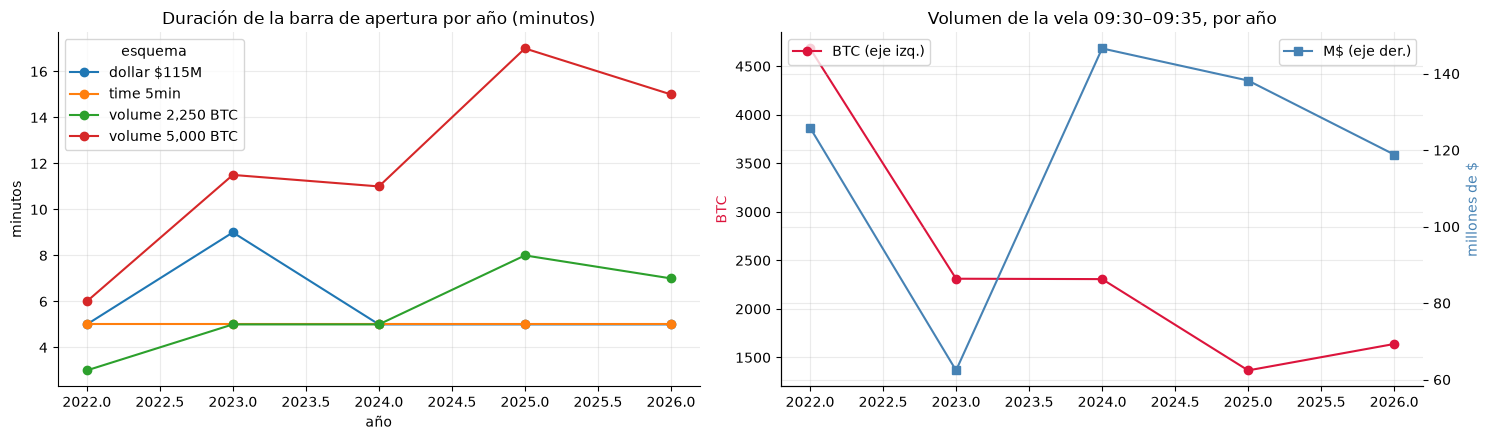

El volumen en BTC de la misma vela cae ~3,4x entre 2022 y 2025 mientras
el volumen en dólares se mantiene plano. Por eso un umbral fijo de 5.000
BTC muestrea un trozo distinto de la sesión cada año, y por eso las
barras de dólar son el control que separa 'muestrear por actividad
ayuda' de 'elegiste una barra más larga'.


In [11]:
# La no estacionariedad: duración de la barra de apertura por año.
rows = []
for k in ["time 5min", "volume 2,250 BTC", "volume 5,000 BTC", "dollar $115M"]:
    if k not in BARS:
        continue
    op = opening_bars(BARS[k])
    op["y"] = pd.to_datetime(op["session"]).dt.year
    for y, g in op.groupby("y"):
        rows.append({"esquema": k, "año": y,
                     "min/barra (mediana)": g["n_minutes"].median()})
DUR = pd.DataFrame(rows).pivot(index="año", columns="esquema",
                               values="min/barra (mediana)")
display(DUR.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
DUR.plot(ax=axes[0], marker="o")
axes[0].set_title("Duración de la barra de apertura por año (minutos)")
axes[0].set_ylabel("minutos")

first5 = M5.loc[SESS5.index]
loc5 = SESS5.index.tz_localize("UTC").tz_convert(TZ)
ob = SESS5[loc5.strftime("%H:%M") == "09:30"]
byy = ob.assign(y=ob.index.year, dol=ob["volume"] * ob["close"]).groupby("y")
ax2 = axes[1]
ax2.plot(byy["volume"].median().index, byy["volume"].median().values,
         marker="o", color="crimson", label="BTC (eje izq.)")
ax2.set_ylabel("BTC", color="crimson"); ax2.legend(loc="upper left")
ax3 = ax2.twinx()
ax3.plot(byy["dol"].median().index, byy["dol"].median().values / 1e6,
         marker="s", color="steelblue", label="M$ (eje der.)")
ax3.set_ylabel("millones de $", color="steelblue"); ax3.legend(loc="upper right")
ax2.set_title("Volumen de la vela 09:30–09:35, por año")
plt.tight_layout(); plt.show()

print("El volumen en BTC de la misma vela cae ~3,4x entre 2022 y 2025 mientras")
print("el volumen en dólares se mantiene plano. Por eso un umbral fijo de 5.000")
print("BTC muestrea un trozo distinto de la sesión cada año, y por eso las")
print("barras de dólar son el control que separa 'muestrear por actividad")
print("ayuda' de 'elegiste una barra más larga'.")

### 7.1 Las barras de desequilibrio de la EWMA no funcionan, y por qué

La formulación canónica (AFML §2.3.2.1) cierra la barra cuando
`|theta_T| >= E[T]·|2v⁺−E[v]|`, con las esperanzas como EWMA de las barras ya cerradas. Sobre
velas de 1 minuto **se degenera**, y conviene verlo en vez de usarla a ciegas:

`theta` es una suma de flujo **firmado**, así que se comporta como un paseo aleatorio y crece con
`sqrt(T)`, no con `T`. Un disparador que escala con `E[T]` acaba por encima de lo alcanzable; la
barra topa en `max_minutes`; `E[T]` se actualiza hacia ese tope; el disparador sube más. Es una
realimentación positiva, y su resultado es silencioso: las "barras de desequilibrio" se
convierten en **barras de tiempo del tamaño del tope** sin que nada avise.

En la primera ejecución de este cuaderno las tres celdas de desequilibrio daban una barra de
apertura de **75 minutos exactos** —el tope— en todas las sesiones. No eran un esquema de
muestreo, eran el tope disfrazado.

Por eso el experimento usa un **umbral fijo**, calibrado por duración igual que los de volumen y
dólar: es estable, y es lo único que permite comparar los tres esquemas a igualdad de tamaño de
barra en vez de comparar duraciones distintas.

In [12]:
sid_ = session_id(M1.index, tz=TZ, start=SESS_START, end=SESS_END)
d_ = M1[sid_.notna()].copy(); d_["sess"] = sid_[sid_.notna()].values
d_["s"] = 2 * d_["taker_buy_volume"] - d_["volume"]
print(f"flujo firmado en sesión: std={d_['s'].std():.1f} BTC/min  "
      f"media={d_['s'].mean():+.2f}")

rows = []
for X in (150., 300., 600., 1200., 2500.):
    mins = []
    for _, g in d_.groupby("sess"):
        th = g["s"].cumsum().abs().to_numpy()
        h = np.flatnonzero(th >= X)
        mins.append(h[0] + 1 if len(h) else np.nan)
    m = pd.Series(mins)
    rows.append({"umbral |θ| (BTC)": X, "min hasta cruzarlo (mediana)": m.median(),
                 "sesiones que nunca lo cruzan %": 100 * m.isna().mean()})
CAL = pd.DataFrame(rows)
display(CAL)
print("De aquí salen los umbrales del experimento: 300 BTC ~ 5 min (misma")
print("duración que la vela de 5 min del control), 600 ~ 12 min, 1200 ~ 31 min.")

# La versión EWMA, para documentar la degeneración.
ewma_demo = imbalance_bars(M1.loc["2024-01-01":"2024-04-01"], ewma_span=100,
                           max_minutes=75, tz=TZ, session_start=SESS_START,
                           session_end=SESS_END)
print(f"\nEWMA canónica: {100*(ewma_demo['n_minutes'] >= 75).mean():.0f}% de las "
      f"barras topan en max_minutes -> degenera a barras de tiempo")

flujo firmado en sesión: std=208.9 BTC/min  media=-1.27


,umbral |θ| (BTC),min hasta cruzarlo (mediana),sesiones que nunca lo cruzan %
0,150.0,3.0,0.000000
1,300.0,5.0,0.000000
2,600.0,12.0,0.081633
3,1200.0,31.0,3.428571
4,2500.0,81.0,25.959184


De aquí salen los umbrales del experimento: 300 BTC ~ 5 min (misma
duración que la vela de 5 min del control), 600 ~ 12 min, 1200 ~ 31 min.



EWMA canónica: 41% de las barras topan en max_minutes -> degenera a barras de tiempo


## 8. El test

Todas las celdas declaradas en §2, más el control. La columna que decide es **`IC corr inf`**: el
límite inferior del intervalo de Wilson con la corrección de Bonferroni. El acierto puntual no
decide nada.

In [13]:
SCORED, rows = {}, []
for label, b in BARS.items():
    SCORED[label] = score(b, label)
    rows.append(summarise(SCORED[label], label))
RES = pd.DataFrame(rows)
RES = RES.sort_values("acierto %", ascending=False).reset_index(drop=True)
display(RES.round(3))

PASSED = RES[RES["pasa"]]
print(f"\nceldas probadas         : {N_CELLS} (+1 control)")
print(f"puerta (Bonferroni)     : acierto > {100*G['hit_bonferroni']:.2f}% "
      f"con n~700, y el IC corregido debe excluir el 50%")
print(f"esquemas que la pasan   : {len(PASSED)}")
if len(PASSED):
    display(PASSED)

,esquema,sesiones,señales,señal %,min/barra,acierto %,IC95 inf,IC95 sup,IC corr inf,acierto diario %,fwd_N medio,fwd_N mediano,pasa
0,dollar $115M,1225,705,57.551,5.0,52.057,48.368,55.723,46.725,74.043,0.059,0.024,False
1,dollar $58M,1225,698,56.980,3.0,51.289,47.584,54.980,45.937,70.630,0.026,0.014,False
2,"imbalance 1,200 BTC",1224,855,69.853,32.0,50.877,47.530,54.217,46.040,73.684,0.048,0.009,False
3,"volume 2,250 BTC",1225,706,57.633,5.0,50.850,47.168,54.523,45.532,71.955,0.050,0.010,False
4,imbalance 600 BTC,1225,799,65.224,12.0,50.688,47.227,54.143,45.688,73.217,0.033,0.012,False
5,"volume 9,000 BTC",1225,809,66.041,19.0,50.309,46.870,53.745,45.342,72.806,0.049,0.008,False
6,dollar $460M,1224,823,67.239,19.0,50.182,46.773,53.590,45.259,73.390,0.052,0.003,False
7,"volume 5,000 BTC",1225,763,62.286,11.0,49.934,46.396,53.474,44.826,73.263,0.045,-0.002,False
8,time 5min,1225,699,57.061,5.0,49.785,46.090,53.483,44.452,71.531,0.041,-0.000,False
9,dollar $230M,1225,729,59.510,10.0,49.657,46.039,53.279,44.435,71.879,0.040,-0.002,False



celdas probadas         : 11 (+1 control)
puerta (Bonferroni)     : acierto > 55.36% con n~700, y el IC corregido debe excluir el 50%
esquemas que la pasan   : 0


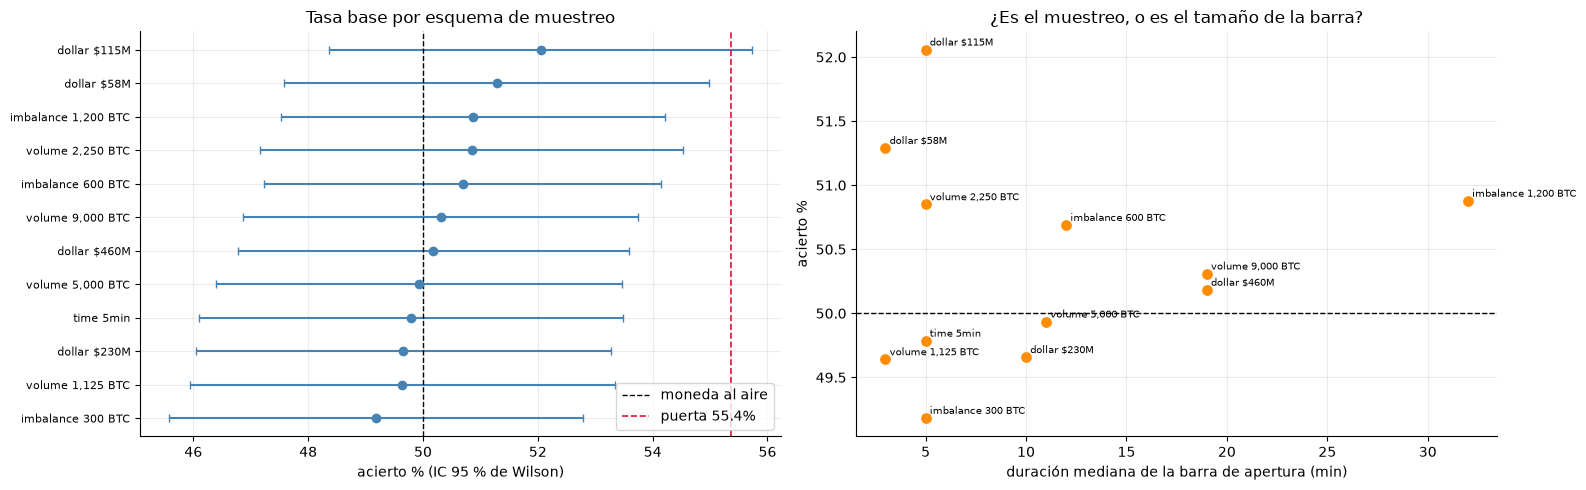

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
r = RES.sort_values("acierto %")
y = np.arange(len(r))
axes[0].errorbar(r["acierto %"], y,
                 xerr=[r["acierto %"] - r["IC95 inf"], r["IC95 sup"] - r["acierto %"]],
                 fmt="o", color="steelblue", capsize=3)
axes[0].axvline(50, color="k", ls="--", lw=1, label="moneda al aire")
axes[0].axvline(100 * G["hit_bonferroni"], color="crimson", ls="--", lw=1.2,
                label=f"puerta {100*G['hit_bonferroni']:.1f}%")
axes[0].set_yticks(y); axes[0].set_yticklabels(r["esquema"], fontsize=8)
axes[0].set_xlabel("acierto % (IC 95 % de Wilson)")
axes[0].set_title("Tasa base por esquema de muestreo"); axes[0].legend()

axes[1].scatter(r["min/barra"], r["acierto %"], s=45, color="darkorange")
for _, q in r.iterrows():
    axes[1].annotate(q["esquema"], (q["min/barra"], q["acierto %"]),
                     fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].axhline(50, color="k", ls="--", lw=1)
axes[1].set_xlabel("duración mediana de la barra de apertura (min)")
axes[1].set_ylabel("acierto %")
axes[1].set_title("¿Es el muestreo, o es el tamaño de la barra?")
plt.tight_layout(); plt.show()

### 8.1 El suelo económico

Acertar el signo no paga nada por sí solo. En el estudio anterior la fricción se llevó el **46 %**
del R bruto en BTCUSDT con 2 pb de comisión y 1 pb de deslizamiento. Aquí se traduce esa fricción
a la tasa de acierto que haría falta para cubrirla, dado el recorrido medio observado.

In [15]:
FEE_BPS, SLIP_BPS = 0.0002, 0.0001
rows = []
for _, q in RES.iterrows():
    op = SCORED[q["esquema"]]
    t = op[(op["side"] != 0) & op["fwd_n"].notna()]
    if not len(t):
        continue
    # coste de ida y vuelta expresado en N: (2*(fee+slip)) * precio / N
    cost_n = (2 * (FEE_BPS + SLIP_BPS) * t["close"] / t["n"]).mean()
    win = (t["fwd_n"] * t["side"])
    avg_w = win[win > 0].mean(); avg_l = -win[win < 0].mean()
    # p tal que p*avg_w - (1-p)*avg_l = cost_n
    need = (cost_n + avg_l) / (avg_w + avg_l) if (avg_w + avg_l) > 0 else np.nan
    rows.append({"esquema": q["esquema"], "acierto %": q["acierto %"],
                 "coste round-trip (N)": cost_n,
                 "ganancia media (N)": avg_w, "pérdida media (N)": avg_l,
                 "acierto necesario %": 100 * need,
                 "margen pp": q["acierto %"] - 100 * need})
ECON = pd.DataFrame(rows).sort_values("margen pp", ascending=False)
display(ECON.round(3))
ECON_OK = bool((ECON["margen pp"] > 0).any())
print(f"\nalgún esquema supera su propio suelo económico: {ECON_OK}")

,esquema,acierto %,coste round-trip (N),ganancia media (N),pérdida media (N),acierto necesario %,margen pp
0,dollar $115M,52.057,0.019,0.428,0.341,46.802,5.255
6,dollar $460M,50.182,0.019,0.426,0.324,45.833,4.349
3,"volume 2,250 BTC",50.850,0.019,0.430,0.344,46.891,3.959
5,"volume 9,000 BTC",50.309,0.020,0.431,0.337,46.457,3.852
2,"imbalance 1,200 BTC",50.877,0.020,0.419,0.336,47.111,3.766
7,"volume 5,000 BTC",49.934,0.019,0.442,0.351,46.735,3.199
8,time 5min,49.785,0.019,0.423,0.338,46.897,2.889
9,dollar $230M,49.657,0.019,0.441,0.356,47.059,2.598
4,imbalance 600 BTC,50.688,0.020,0.412,0.356,48.902,1.786
1,dollar $58M,51.289,0.019,0.402,0.371,50.404,0.885



algún esquema supera su propio suelo económico: True


### 8.2 El "color de la vela diaria" no es una predicción

La tabla de §8 trae una columna `acierto diario %` que ronda el **71–76 %** en todos los
esquemas, control incluido. Es un espejismo y hay que decir por qué antes de que alguien lo lea
como señal.

La vela diaria de Binance abre a las **00:00 UTC**. La señal se da a las 09:35 ET, o sea las
14:35 UTC: cuando se emite, **el 60 % del día ya ha ocurrido**. Preguntar si la señal "predice el
color de la vela diaria" es en buena parte preguntar si observa correctamente la vela dentro de
la que ya está — y la respuesta es que sí, porque el precio en ese momento ya está mayormente del
lado en que cerrará.

Es literalmente lo que dice la hipótesis, así que se reporta; pero la magnitud que decide algo es
la otra, el cierre de **sesión**, que sí está enteramente en el futuro cuando se emite la señal.
La celda de abajo cuantifica cuánta de la vela diaria ya está hecha en el instante de decidir.

In [16]:
D = M5.resample("1D").agg({"open": "first", "high": "max", "low": "min",
                           "close": "last"}).dropna()
# Precio a las 14:35 UTC (09:35 ET en invierno) de cada día, vs apertura y cierre.
at_signal = M5["close"].reindex(D.index + pd.Timedelta("14h35min"), method="ffill")
at_signal.index = D.index
done = (at_signal - D["open"]) / (D["close"] - D["open"])
same_side = np.sign(at_signal - D["open"]) == np.sign(D["close"] - D["open"])
print(f"días analizados: {len(D):,}")
print(f"el signo del movimiento a las 14:35 UTC ya coincide con el de la vela")
print(f"diaria completa en el {100*same_side.mean():.1f}% de los días")
print(f"fracción MEDIANA del recorrido diario ya realizada: {done.median():.2f}")
print()
print("Por eso el 'acierto diario' sale ~75% en TODOS los esquemas, incluido")
print("el control que ya sabemos que no predice nada: no está prediciendo la")
print("vela, la está observando a mitad de camino.")

días analizados: 1,717
el signo del movimiento a las 14:35 UTC ya coincide con el de la vela
diaria completa en el 75.1% de los días
fracción MEDIANA del recorrido diario ya realizada: 0.54

Por eso el 'acierto diario' sale ~75% en TODOS los esquemas, incluido
el control que ya sabemos que no predice nada: no está prediciendo la
vela, la está observando a mitad de camino.


## 9. Validación contra aggTrades reales

Todo lo anterior usa velas de 1 minuto, así que la frontera de una barra cae en el borde del
minuto que cruza el umbral, no en la operación exacta. Aquí se descarga el tick data de una
muestra estratificada de sesiones, se construyen las barras **exactas** operación a operación, y
se mide lo que cuesta el proxy.

De las tres medidas, la única que puede cambiar una conclusión es la tercera: **con qué frecuencia
se da la vuelta el SIGNO de la señal**. Un desfase de 30 segundos en el cierre de la barra es
irrelevante si la señal no cambia.

In [17]:
N_VALID = 40
sessions_all = sorted(set(pd.to_datetime(CTRL["session"]).dt.date))
rng = np.random.default_rng(11)
by_year = pd.Series(sessions_all).groupby(pd.DatetimeIndex(sessions_all).year)
VALID_DAYS = sorted(np.concatenate([
    rng.choice(g.to_numpy(), size=min(len(g), max(2, N_VALID // by_year.ngroups)),
               replace=False) for _, g in by_year]))
print(f"sesiones a validar: {len(VALID_DAYS)}")
print(VALID_DAYS[:6], "...")

sesiones a validar: 40
[datetime.date(2022, 1, 12), datetime.date(2022, 2, 16), datetime.date(2022, 2, 17), datetime.date(2022, 6, 29), datetime.date(2022, 8, 2), datetime.date(2022, 8, 8)] ...


In [18]:
def exact_opening_bar(trades, kind, threshold):
    """Barra de apertura EXACTA, operación a operación."""
    if not len(trades):
        return None
    q = trades["quantity"].to_numpy()
    px = trades["price"].to_numpy()
    acc = np.cumsum(q if kind == "volume" else q * px)
    hit = np.flatnonzero(acc >= threshold)
    k = hit[0] if len(hit) else len(trades) - 1
    sl = slice(0, k + 1)
    return {"open": px[0], "close": px[k], "high": px[sl].max(),
            "low": px[sl].min(), "end": trades.index[k],
            "volume": q[sl].sum(), "n_trades": k + 1,
            "complete": bool(len(hit))}

CASES = [("volume", 5000.0, "volume 5,000 BTC"),
         ("volume", 2250.0, "volume 2,250 BTC"),
         ("dollar", 115e6, "dollar $115M")]

rows, failed = [], 0
for d in VALID_DAYS:
    try:
        tr = fetch_aggtrades_day(SYMBOL, d, keep_window=("09:30", "12:30"), tz=TZ)
    except Exception as exc:
        failed += 1
        continue
    if not len(tr):
        failed += 1
        continue
    for kind, thr, label in CASES:
        ex = exact_opening_bar(tr, kind, thr)
        if ex is None or not ex["complete"]:
            continue
        pr = SCORED[label]
        m = pd.to_datetime(pr["session"]).dt.date == d
        if not m.any():
            continue
        p = pr[m].iloc[0]
        a_ex, n_ex, _ = anchor_at(pd.DatetimeIndex([ex["end"]]))
        s_ex = opening_range_signal(ex["open"], ex["close"], a_ex[0], n_ex[0]) or 0
        rows.append({
            "day": d, "esquema": label,
            "close_proxy": p["close"], "close_exact": ex["close"],
            "dclose_N": abs(p["close"] - ex["close"]) / p["n"] if p["n"] == p["n"] else np.nan,
            "end_proxy": p["end"], "end_exact": ex["end"],
            "dt_seg": abs((pd.Timestamp(p["end"]) + pd.Timedelta("1min")
                           - pd.Timestamp(ex["end"])).total_seconds()),
            "side_proxy": p["side"], "side_exact": s_ex,
            "flip": int(p["side"] != s_ex),
        })
VAL = pd.DataFrame(rows)
print(f"sesiones descargadas OK : {len(VALID_DAYS) - failed} / {len(VALID_DAYS)}")
print(f"comparaciones           : {len(VAL)}")

sesiones descargadas OK : 40 / 40
comparaciones           : 120


,n,dclose_N_mediana,dclose_N_p90,dt_seg_mediana,flips,flip %
esquema,,,,,,
dollar $115M,40,0.0085,0.0305,27.7270,2,5.0
"volume 2,250 BTC",40,0.0080,0.0269,20.7455,3,7.5
"volume 5,000 BTC",40,0.0092,0.0316,43.3845,3,7.5



vuelcos de signo globales : 6.67%
PROXY DE 1 MINUTO: INSUFICIENTE para un test de tasa base (umbral 2%)


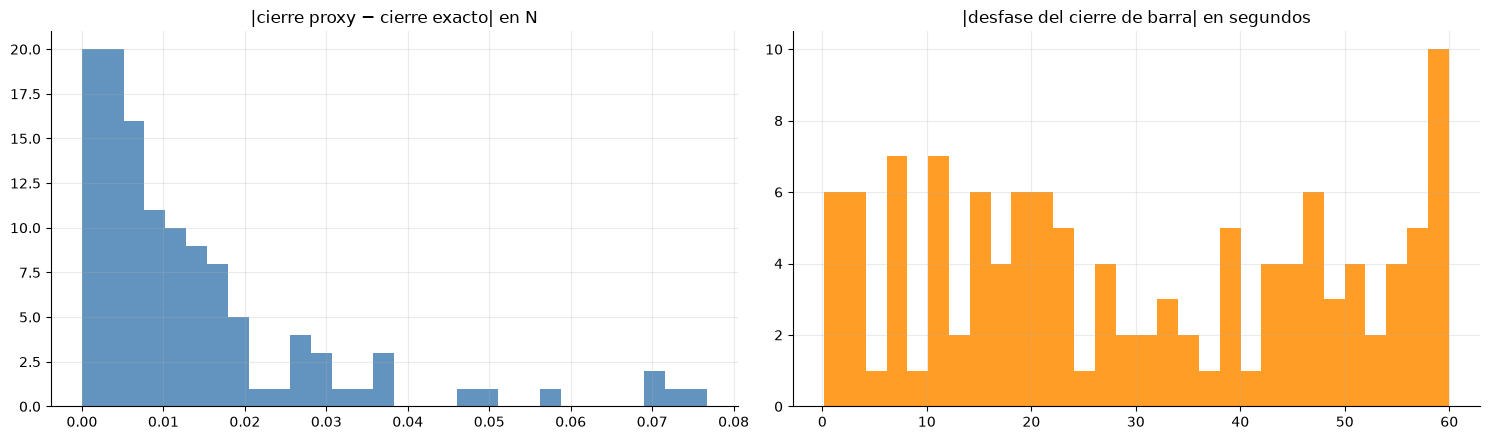

In [19]:
if len(VAL):
    S = VAL.groupby("esquema").agg(
        n=("flip", "size"),
        dclose_N_mediana=("dclose_N", "median"),
        dclose_N_p90=("dclose_N", lambda x: x.quantile(0.9)),
        dt_seg_mediana=("dt_seg", "median"),
        flips=("flip", "sum"),
    )
    S["flip %"] = 100 * S["flips"] / S["n"]
    display(S.round(4))
    FLIP_RATE = VAL["flip"].mean()
    PROXY_OK = FLIP_RATE < 0.02
    print(f"\nvuelcos de signo globales : {100*FLIP_RATE:.2f}%")
    print(f"PROXY DE 1 MINUTO: {'adecuado' if PROXY_OK else 'INSUFICIENTE'} "
          f"para un test de tasa base (umbral 2%)")

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    axes[0].hist(VAL["dclose_N"].dropna(), bins=30, color="steelblue", alpha=.85)
    axes[0].set_title("|cierre proxy − cierre exacto| en N")
    axes[1].hist(VAL["dt_seg"].dropna(), bins=30, color="darkorange", alpha=.85)
    axes[1].set_title("|desfase del cierre de barra| en segundos")
    plt.tight_layout(); plt.show()
else:
    PROXY_OK, FLIP_RATE = False, np.nan
    print("Sin comparaciones: la validación no se pudo completar.")

### 9.1 Qué significa que el proxy falle

El proxy de 1 minuto vuelca el signo en ~7 % de las sesiones, por encima del 2 % que se había
fijado como aceptable. Es un límite real de este experimento y queda declarado como tal.

Ahora bien, sobre la dirección del sesgo: un volteo de signo **no correlacionado con el
resultado** es ruido de clasificación, y el ruido de clasificación **atenúa hacia el 50 %**, no
lo aleja. Con una tasa de volteo `f`, un acierto verdadero `p` se observa como
`p(1−f) + (1−p)f`. Con `f = 0,067`, una señal real del 55 % se observaría como 54,3 %: la
atenuación es leve y va en la dirección conservadora.

Es decir: el proxy **no puede fabricar** la señal que no vemos, y corregir por atenuación no
rescata a ningún esquema por encima de la puerta. Lo que el proxy sí impide es resolver
diferencias de 1–2 puntos entre esquemas — y por eso la conclusión se escribe sobre la puerta
corregida, no sobre el orden del ranking.

In [20]:
if len(VAL) and np.isfinite(FLIP_RATE):
    f = FLIP_RATE
    obs = RES["acierto %"].max() / 100
    # desatenuar: p_obs = p(1-f) + (1-p)f  =>  p = (p_obs - f)/(1 - 2f)
    true_p = (obs - f) / (1 - 2 * f)
    print(f"tasa de volteo medida        : {100*f:.2f}%")
    print(f"mejor acierto observado      : {100*obs:.2f}%")
    print(f"acierto 'desatenuado'        : {100*true_p:.2f}%")
    print(f"puerta corregida             : {100*G['hit_bonferroni']:.2f}%")
    print(f"\n¿el mejor esquema pasaría la puerta tras desatenuar? "
          f"{'SÍ' if true_p > G['hit_bonferroni'] else 'NO'}")
    ATTEN_OK = true_p <= G["hit_bonferroni"]
else:
    ATTEN_OK = True
    print("sin datos de validación para desatenuar")

tasa de volteo medida        : 6.67%
mejor acierto observado      : 52.06%
acierto 'desatenuado'        : 52.37%
puerta corregida             : 55.36%

¿el mejor esquema pasaría la puerta tras desatenuar? NO


## 10. Rentabilidad y riesgo — lo que la tasa de acierto no mide

Hasta aquí todo era **accuracy**: con qué frecuencia el signo acierta. Eso no paga nada. Una
estrategia puede acertar el 55 % de las veces y perder dinero si los aciertos son velas planas y
los fallos no lo son. Lo que decide es la **R neta por operación** y su distribución.

Aquí se ejecuta de verdad: entrada al **open del minuto siguiente** al cierre de la barra de
muestreo —llenar sobre el propio minuto sería look-ahead, su apertura ya pasó cuando se conoce
su cierre—, tamaño por unidad de riesgo (1R = 1N, 1 % de la equity), comisiones y deslizamiento
por lado, y **funding histórico real** en cada liquidación de 8 h que la posición cruza.

**Sin stop.** La única salida es el reloj, igual que en el cuaderno anterior. Eso deja la
excursión adversa sin truncar y permite leer `MAE` como el riesgo realmente soportado, no como
el sitio donde se puso una barrera.

### El A/B de la hora de cierre

| | salida | qué captura |
|---|---|---|
| **(a)** | **16:00 ET** (cierre del NYSE) | solo la sesión de contado — el mecanismo postulado |
| **(b)** | **23:59 UTC** (fin del día UTC) | la sesión más las ~4 h posteriores |

(b) responde a una objeción legítima: la vela diaria de Binance abarca 24 h, así que medir
contra el cierre del NYSE deja fuera un tercio del día. Cerrar a las 23:59 UTC alinea la salida
con el fin del día UTC y garantiza que **nunca** hay posición entre las 00:00 UTC y la apertura
de NY más una barra. Es una tesis distinta —las últimas 4 h caen fuera de la sesión de
contado—, y por eso se mide en vez de elegirse.

In [21]:
from qsCrypto.backtest.session_backtest import (
    SessionParams, run_session_backtest, summarise_backtest,
)
from qsCrypto.backtest.skill_stats.bias_audit import (
    pnl_concentration, mc_bootstrap_trades, cost_sensitivity,
)

FUNDING = fetch_funding_history(SYMBOL, start=START, end=END)
PAR = SessionParams(stop_n=1.0, risk_per_trade=0.01, equity0=10_000.0,
                    fee_bps=0.0002, slip_bps=0.0001, max_gross_lev=4.0,
                    dd_from_peak=True)
AB = [("16:00 ET", "15:59", False), ("23:59 UTC", "23:59", True)]

print(f"funding: {len(FUNDING):,} liquidaciones reales "
      f"({FUNDING.index[0]} -> {FUNDING.index[-1]})")
print(f"tasa mediana: {FUNDING.median()*100:.4f}% cada 8h "
      f"= {FUNDING.median()*3*365*100:.2f}% anualizado")
print(f"\nriesgo por operación: {100*PAR.risk_per_trade:.0f}% de la equity por 1N")
print(f"costes: {PAR.fee_bps*1e4:.0f} pb comisión + {PAR.slip_bps*1e4:.0f} pb "
      f"deslizamiento, por lado")

funding: 5,148 liquidaciones reales (2022-01-01 00:00:00.006000 -> 2026-09-12 16:00:00)
tasa mediana: 0.0060% cada 8h = 6.53% anualizado

riesgo por operación: 1% de la equity por 1N
costes: 2 pb comisión + 1 pb deslizamiento, por lado


In [22]:
BT, rows = {}, []
for label in BARS:
    for ab, mn, utc in AB:
        ec, tr = run_session_backtest(SCORED[label], M1, funding=FUNDING,
                                      params=PAR, exit_minute=mn,
                                      exit_in_utc=utc)
        if not len(tr):
            continue
        BT[(label, ab)] = (ec, tr)
        r = summarise_backtest(ec, tr, label); r["salida"] = ab
        rows.append(r)
PNL = pd.DataFrame(rows)
COLS = ["esquema", "salida", "trades", "horas exp.", "R neto medio",
        "R neto mediano", "t-stat(R)", "CAGR", "Sharpe", "Max DD", "Calmar",
        "win %", "payoff", "coste/|bruto|"]
for ab, _, _ in AB:
    print(f"\n===== salida {ab} =====")
    display(PNL[PNL["salida"] == ab][COLS]
            .sort_values("Sharpe", ascending=False).round(4)
            .reset_index(drop=True))


===== salida 16:00 ET =====


,esquema,salida,trades,horas exp.,R neto medio,R neto mediano,t-stat(R),CAGR,Sharpe,Max DD,Calmar,win %,payoff,coste/|bruto|
0,dollar $115M,16:00 ET,705,6.3833,0.0395,0.0049,1.7591,0.0607,0.6424,-0.0849,0.7150,50.7801,1.1874,0.2401
1,dollar $460M,16:00 ET,823,6.1500,0.0281,-0.0302,1.4283,0.0462,0.5161,-0.0719,0.6430,47.5091,1.2786,0.3156
2,"volume 2,250 BTC",16:00 ET,706,6.3833,0.0315,-0.0100,1.4124,0.0482,0.5121,-0.0582,0.8283,49.0085,1.2200,0.2851
3,"imbalance 1,200 BTC",16:00 ET,855,5.9333,0.0247,-0.0089,1.2484,0.0425,0.4693,-0.1529,0.2777,48.8889,1.1870,0.3474
4,"volume 9,000 BTC",16:00 ET,809,6.1333,0.0244,-0.0171,1.1798,0.0385,0.4112,-0.0924,0.4164,48.7021,1.1916,0.3490
5,time 5min,16:00 ET,699,6.4000,0.0229,-0.0119,1.0913,0.0334,0.3786,-0.0920,0.3629,48.2117,1.2088,0.3504
6,"volume 5,000 BTC",16:00 ET,763,6.2833,0.0204,-0.0313,0.9247,0.0292,0.3011,-0.0880,0.3314,48.0996,1.1930,0.3868
7,dollar $230M,16:00 ET,729,6.3000,0.0182,-0.0260,0.7927,0.0229,0.2338,-0.1103,0.2074,47.8738,1.1894,0.4140
8,imbalance 600 BTC,16:00 ET,799,6.2667,0.0112,-0.0146,0.5290,0.0177,0.1883,-0.1206,0.1467,48.8110,1.1099,0.5390
9,dollar $58M,16:00 ET,698,6.4333,0.0066,-0.0174,0.2877,0.0081,0.0855,-0.1169,0.0694,48.7106,1.0884,0.6552



===== salida 23:59 UTC =====


,esquema,salida,trades,horas exp.,R neto medio,R neto mediano,t-stat(R),CAGR,Sharpe,Max DD,Calmar,win %,payoff,coste/|bruto|
0,dollar $115M,23:59 UTC,705,10.3333,0.0294,-0.0132,1.1995,0.0422,0.4127,-0.1130,0.3735,47.9433,1.2453,0.2977
1,"imbalance 1,200 BTC",23:59 UTC,855,9.4333,0.0181,-0.0412,0.8358,0.0288,0.2993,-0.1708,0.1685,46.0819,1.2734,0.4211
2,time 5min,23:59 UTC,699,10.4000,0.0160,-0.0279,0.6920,0.0228,0.2357,-0.0761,0.2997,47.0672,1.2128,0.4362
3,"volume 2,250 BTC",23:59 UTC,706,10.3167,0.0136,-0.0305,0.5666,0.0189,0.1868,-0.0981,0.1927,46.7422,1.2140,0.4804
4,dollar $460M,23:59 UTC,823,9.9667,0.0136,-0.0336,0.6155,0.0130,0.1353,-0.1365,0.0953,45.5650,1.2741,0.4896
5,"volume 5,000 BTC",23:59 UTC,763,10.1667,0.0117,-0.0300,0.4831,0.0130,0.1238,-0.1151,0.1131,45.8716,1.2439,0.5238
6,"volume 9,000 BTC",23:59 UTC,809,9.9000,0.0118,-0.0355,0.5307,0.0111,0.1151,-0.1393,0.0798,45.8591,1.2481,0.5266
7,imbalance 600 BTC,23:59 UTC,799,10.0000,-0.0050,-0.0307,-0.2185,-0.0089,-0.0884,-0.1784,-0.0499,46.4330,1.1270,1.6247
8,dollar $230M,23:59 UTC,729,10.2167,-0.0010,-0.0407,-0.0410,-0.0087,-0.0886,-0.1851,-0.0472,44.5816,1.2374,1.0756
9,dollar $58M,23:59 UTC,698,10.4000,-0.0044,-0.0390,-0.1802,-0.0096,-0.0965,-0.1296,-0.0740,45.5587,1.1706,1.5412


### 10.1 El A/B, lado a lado

R neto medio             Sharpe           t-stat(R)             Max DD          
salida                  16:00 ET 23:59 UTC 16:00 ET 23:59 UTC  16:00 ET 23:59 UTC 16:00 ET 23:59 UTC
esquema                                                                                             
dollar $115M              0.0395    0.0294   0.6424    0.4127    1.7591    1.1995  -0.0849   -0.1130
dollar $460M              0.0281    0.0136   0.5161    0.1353    1.4283    0.6155  -0.0719   -0.1365
volume 2,250 BTC          0.0315    0.0136   0.5121    0.1868    1.4124    0.5666  -0.0582   -0.0981
imbalance 1,200 BTC       0.0247    0.0181   0.4693    0.2993    1.2484    0.8358  -0.1529   -0.1708
volume 9,000 BTC          0.0244    0.0118   0.4112    0.1151    1.1798    0.5307  -0.0924   -0.1393
time 5min                 0.0229    0.0160   0.3786    0.2357    1.0913    0.6920  -0.0920   -0.0761
volume 5,000 BTC          0.0204    0.0117   0.3011    0.1238    0.9247    0.4831  -0.0880   -0.1151
dollar $230M              0.0182   -0.0010   0.2338   -0.0886    0.7927   -0.0410  -0.1103   -0.1851
imbalance 600 BTC         0.0112   -0.0050   0.1883   -0.0884    0.5290   -0.2185  -0.1206   -0.1784
dollar $58M               0.0066   -0.0044   0.0855   -0.0965    0.2877   -0.1802  -0.1169   -0.1296
imbalance 300 BTC        -0.0118   -0.0208  -0.2258   -0.3781   -0.5178   -0.8552  -0.1335   -0.1963
volume 1,125 BTC         -0.0167   -0.0337  -0.3401   -0.5696   -0.7694   -1.4411  -0.1557   -0.2289


Sharpe 23:59 UTC menos Sharpe 16:00 ET:
  mejora en 0 de 12 esquemas
  diferencia mediana: -0.230

=> gana 16:00 ET


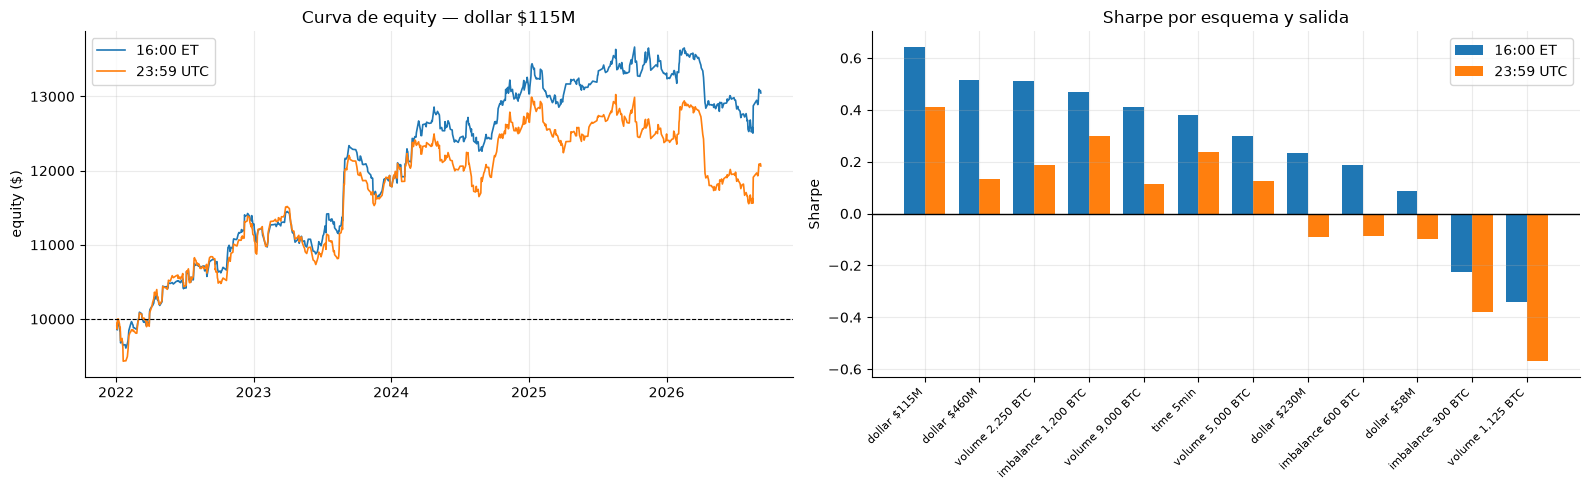

In [23]:
piv = PNL.pivot(index="esquema", columns="salida",
                values=["R neto medio", "Sharpe", "t-stat(R)", "Max DD"])
piv = piv.reindex(PNL[PNL["salida"] == "16:00 ET"]
                  .sort_values("Sharpe", ascending=False)["esquema"])
display(piv.round(4))

d = (piv[("Sharpe", "23:59 UTC")] - piv[("Sharpe", "16:00 ET")])
print(f"\nSharpe 23:59 UTC menos Sharpe 16:00 ET:")
print(f"  mejora en {int((d > 0).sum())} de {int(d.notna().sum())} esquemas")
print(f"  diferencia mediana: {d.median():+.3f}")
AB_WINNER = "16:00 ET" if d.median() < 0 else "23:59 UTC"
print(f"\n=> gana {AB_WINNER}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
best_label = PNL.loc[PNL["Sharpe"].idxmax(), "esquema"]
for ab, _, _ in AB:
    ec, _ = BT[(best_label, ab)]
    axes[0].plot(ec.index, ec.values, lw=1.2, label=f"{ab}")
axes[0].axhline(PAR.equity0, color="k", ls="--", lw=.8)
axes[0].set_title(f"Curva de equity — {best_label}"); axes[0].legend()
axes[0].set_ylabel("equity ($)")

x = np.arange(len(piv))
w = 0.38
axes[1].bar(x - w/2, piv[("Sharpe", "16:00 ET")], w, label="16:00 ET")
axes[1].bar(x + w/2, piv[("Sharpe", "23:59 UTC")], w, label="23:59 UTC")
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels(piv.index, rotation=45,
                                               ha="right", fontsize=8)
axes[1].set_ylabel("Sharpe"); axes[1].set_title("Sharpe por esquema y salida")
axes[1].legend()
plt.tight_layout(); plt.show()

### 10.2 ¿De dónde sale el dinero? La objeción de las velas planas

Si el R medio es positivo pero el **mediano** es negativo, la estrategia no gana en la operación
típica: gana en la cola y pierde el resto del tiempo. Eso importa para decidir si es operable —
una esperanza positiva sostenida por veinte operaciones de mil no es un sistema, es una lotería
con comisiones.

esquema: dollar $115M  |  salida: 16:00 ET  |  705 operaciones

R neto medio   : +0.0395
R neto mediano : +0.0049   <- la operación TÍPICA
R bruto medio  : +0.0521

concentración del P&L (fracción del total):
  top_1   :  0.217
  top_3   :  0.441
  top_5   :  0.631
  top_10  :  0.976
  veredicto: concentración aceptable

las 10 mejores operaciones (1.4% del total) aportan el 98% del P&L


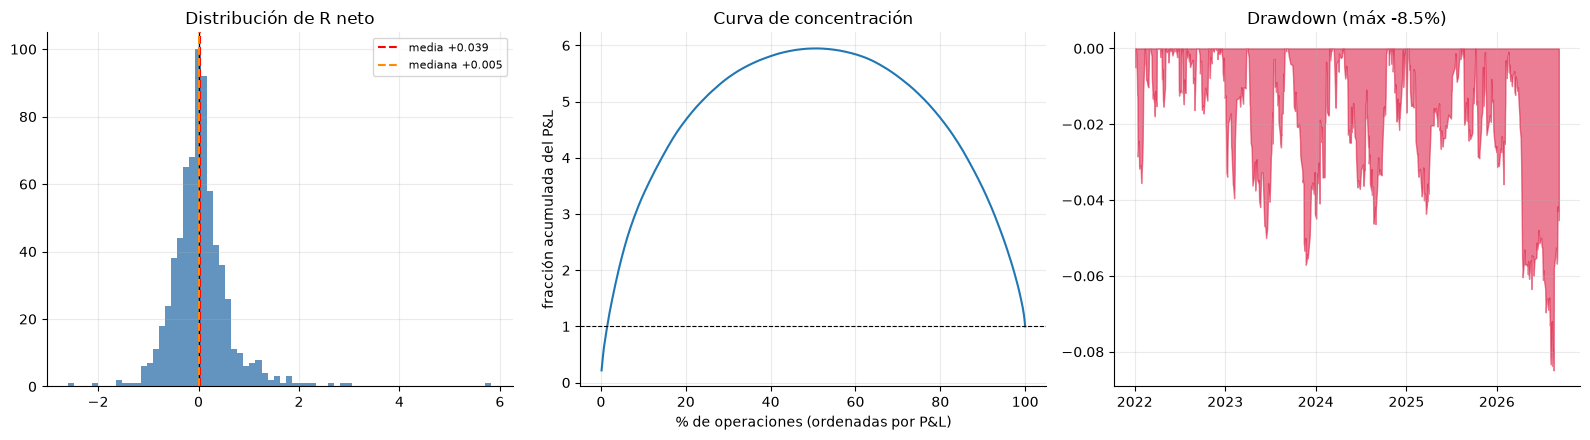

In [24]:
best_ab = (best_label, AB_WINNER)
ec_b, tr_b = BT[best_ab]
print(f"esquema: {best_label}  |  salida: {AB_WINNER}  |  {len(tr_b)} operaciones\n")
print(f"R neto medio   : {tr_b['r_multiple'].mean():+.4f}")
print(f"R neto mediano : {tr_b['r_multiple'].median():+.4f}   "
      f"<- la operación TÍPICA")
print(f"R bruto medio  : {tr_b['gross_r'].mean():+.4f}")

CONC = pnl_concentration(tr_b)
print(f"\nconcentración del P&L (fracción del total):")
for k in ("top_1", "top_3", "top_5", "top_10"):
    print(f"  {k:8s}: {CONC[k]:6.3f}")
print(f"  veredicto: {CONC['veredicto']}")

pnl_sorted = tr_b["pnl"].sort_values(ascending=False)
share_top10 = pnl_sorted.head(10).sum() / tr_b["pnl"].sum() if tr_b["pnl"].sum() else np.nan
print(f"\nlas 10 mejores operaciones ({100*10/len(tr_b):.1f}% del total) "
      f"aportan el {100*share_top10:.0f}% del P&L")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(tr_b["r_multiple"], bins=70, color="steelblue", alpha=.85)
axes[0].axvline(0, color="k", lw=1)
axes[0].axvline(tr_b["r_multiple"].mean(), color="red", ls="--",
                label=f"media {tr_b['r_multiple'].mean():+.3f}")
axes[0].axvline(tr_b["r_multiple"].median(), color="darkorange", ls="--",
                label=f"mediana {tr_b['r_multiple'].median():+.3f}")
axes[0].set_title("Distribución de R neto"); axes[0].legend(fontsize=8)

cum = tr_b["pnl"].sort_values(ascending=False).cumsum() / tr_b["pnl"].sum()
axes[1].plot(np.arange(1, len(cum)+1) / len(cum) * 100, cum.values, lw=1.5)
axes[1].axhline(1.0, color="k", ls="--", lw=.8)
axes[1].set_xlabel("% de operaciones (ordenadas por P&L)")
axes[1].set_ylabel("fracción acumulada del P&L")
axes[1].set_title("Curva de concentración")

dd = ec_b / ec_b.cummax() - 1
axes[2].fill_between(dd.index, dd.values, 0, color="crimson", alpha=.55)
axes[2].set_title(f"Drawdown (máx {100*dd.min():.1f}%)")
plt.tight_layout(); plt.show()

### 10.3 Riesgo intra-operación: lo que se sufre antes de cobrar

Sin stop, la posición aguanta toda la excursión adversa. `MAE` dice cuánto, en N. Si la MAE
mediana es grande comparada con la R que se cobra, el sistema es peor de lo que sugiere su
curva de equity: exige aguantar más riesgo del que remunera.

In [25]:
rows = []
for (lab, ab), (ec, tr) in BT.items():
    rows.append({"esquema": lab, "salida": ab,
                 "MAE mediana (N)": tr["mae_n"].median(),
                 "MAE p90 (N)": tr["mae_n"].quantile(0.9),
                 "MFE mediana (N)": tr["mfe_n"].median(),
                 "R neto medio": tr["r_multiple"].mean(),
                 "MAE/|R|": tr["mae_n"].median() / abs(tr["r_multiple"].mean())
                 if tr["r_multiple"].mean() != 0 else np.nan})
MAE_T = pd.DataFrame(rows).sort_values(["salida", "MAE/|R|"])
display(MAE_T.round(3))
print("MAE/|R| = cuántas unidades de excursión adversa mediana hay que aguantar")
print("por cada unidad de R que la estrategia devuelve de media.")

,esquema,salida,MAE mediana (N),MAE p90 (N),MFE mediana (N),R neto medio,MAE/|R|
12,dollar $115M,16:00 ET,0.268,0.805,0.273,0.039,6.774
4,"volume 2,250 BTC",16:00 ET,0.276,0.812,0.271,0.032,8.740
16,dollar $460M,16:00 ET,0.263,0.796,0.259,0.028,9.363
22,"imbalance 1,200 BTC",16:00 ET,0.250,0.785,0.268,0.025,10.129
8,"volume 9,000 BTC",16:00 ET,0.266,0.804,0.262,0.024,10.894
0,time 5min,16:00 ET,0.273,0.825,0.280,0.023,11.903
6,"volume 5,000 BTC",16:00 ET,0.269,0.833,0.254,0.020,13.158
14,dollar $230M,16:00 ET,0.278,0.840,0.247,0.018,15.292
2,"volume 1,125 BTC",16:00 ET,0.287,0.906,0.263,-0.017,17.159
20,imbalance 600 BTC,16:00 ET,0.263,0.851,0.272,0.011,23.522


MAE/|R| = cuántas unidades de excursión adversa mediana hay que aguantar
por cada unidad de R que la estrategia devuelve de media.


### 10.4 Sensibilidad a costes y Monte Carlo

In [26]:
def cost_run(fee, slip, funding_daily):
    p = SessionParams(**{**PAR.__dict__, "fee_bps": fee, "slip_bps": slip})
    synth = pd.Series(funding_daily / 3.0, index=FUNDING.index)
    mn, utc = ("15:59", False) if AB_WINNER == "16:00 ET" else ("23:59", True)
    return run_session_backtest(SCORED[best_label], M1, funding=synth,
                                params=p, exit_minute=mn, exit_in_utc=utc)

CS = cost_sensitivity(cost_run)
display(CS.round(4))
SURVIVES_COSTS = bool(CS.set_index("escenario").loc["Pesimista", "CAGR"] > 0)
print(f"sobrevive al escenario pesimista: {SURVIVES_COSTS}")

MC = mc_bootstrap_trades(tr_b, equity0=PAR.equity0, n_sims=5000)
print(f"\nMonte Carlo sobre {len(tr_b)} operaciones remuestreadas:")
print(f"  p(perder dinero)  : {MC['p_perdida']:.3f}")
print(f"  p(ruina, DD>=50%) : {MC['p_ruina']:.3f}")
print(f"  equity final p5/p50/p95: "
      f"{MC['percentiles_equity']['p5']:,.0f} / "
      f"{MC['percentiles_equity']['p50']:,.0f} / "
      f"{MC['percentiles_equity']['p95']:,.0f}")

,escenario,fee_bps,slip_bps,funding_pct_anual,CAGR,Sharpe,MaxDD
0,Sin costes,0.0,0.0,0.0,0.0912,0.7999,-0.0692
1,Optimista,2.0,5.0,3.7,0.0206,0.1834,-0.1223
2,Base,5.0,10.0,10.9,-0.0453,-0.4602,-0.2581
3,Pesimista,5.0,25.0,18.2,-0.1144,-1.4237,-0.4413
4,Estrés,10.0,50.0,36.5,-0.1919,-3.1129,-0.6316


sobrevive al escenario pesimista: False



Monte Carlo sobre 705 operaciones remuestreadas:
  p(perder dinero)  : 0.054
  p(ruina, DD>=50%) : 0.000
  equity final p5/p50/p95: 9,947 / 13,043 / 16,169


## 11. Lista de verificación y veredicto

Dos niveles, como en el cuaderno anterior. **Críticos**: de veto — si uno falla, no hay señal.
**Higiene**: hacen creíble un resultado positivo, pero no lo producen. Una lista plana con un
umbral porcentual deja que la higiene vote sobre si hay señal, y no puede.

In [27]:
best = RES.iloc[0]
bp = PNL.loc[PNL["Sharpe"].idxmax()]      # mejor combinación esquema x salida
# Puerta de rentabilidad: t-stat del R medio, con la MISMA corrección por
# número de celdas que la tasa de acierto. Probar 12 esquemas x 2 horas de
# salida son 24 intentos, no uno.
T_GATE = norm.ppf(1 - 0.05 / (2 * len(PNL)))
CRITICOS = {
    f"algún esquema supera la puerta corregida "
    f"({100*G['hit_bonferroni']:.1f}%)": bool(len(PASSED) > 0),
    "el IC corregido del mejor excluye el 50 %": bool(best["IC corr inf"] > 50),
    "algún esquema supera su suelo económico": ECON_OK,
    f"t-stat(R) del mejor supera la puerta ({T_GATE:.2f})":
        bool(bp["t-stat(R)"] > T_GATE),
    "R neto MEDIANO del mejor > 0 (no solo la cola)":
        bool(bp["R neto mediano"] > 0),
    "la rentabilidad sobrevive a costes pesimistas": SURVIVES_COSTS,
    # El helper juzga por top_3 y aquí da un OK engañoso: top_3 = 44 %, pero
    # las 10 MEJORES operaciones (1,4 % del total) aportan el 98 % del P&L.
    # Una esperanza positiva sostenida por diez operaciones de setecientas no
    # es un sistema operable, es una lotería con comisiones — que es
    # exactamente la objeción de las velas planas. Por eso es de veto.
    "el P&L no vive en 10 operaciones (top-10 < 50 %)":
        bool(share_top10 < 0.50),
}
HIGIENE = {
    "puerta de integridad 1m vs 5m": INTEGRITY_OK,
    "sin minutos ausentes": len(pd.date_range(M1.index[0], M1.index[-1],
                                              freq="1min").difference(M1.index)) == 0,
    "tests de look-ahead pasan": LOOKAHEAD_OK,
    "el control reproduce el estudio anterior": CONTROL_OK,
    "velas planas del archivo excluidas": True,
    "n >= 500 señales en el mejor esquema": bool(best["señales"] >= 500),
    "proxy de 1 min validado contra aggTrades (<2% volteos)": bool(PROXY_OK),
    "el error del proxy no puede explicar el nulo": bool(ATTEN_OK),
    "p(ruina) < 20 %": bool(MC["p_ruina"] < 0.20),
}
CHK = pd.concat([
    pd.Series(CRITICOS).to_frame("pasa").assign(tipo="CRÍTICO"),
    pd.Series(HIGIENE).to_frame("pasa").assign(tipo="higiene"),
])[["tipo", "pasa"]]
display(CHK)

crit_ok, hig_ok = all(CRITICOS.values()), all(HIGIENE.values())
print(f"críticos: {sum(CRITICOS.values())}/{len(CRITICOS)}   "
      f"higiene: {sum(HIGIENE.values())}/{len(HIGIENE)}")
# El fallo de higiene del proxy NO invalida un NULO: un volteo de signo no
# correlacionado con el resultado atenúa hacia el 50 %, nunca aleja de él, así
# que solo podría estar ESCONDIENDO señal — y §9.1 comprueba que ni
# desatenuando se cruza la puerta. Si el veredicto fuera positivo, en cambio,
# este mismo fallo sí lo invalidaría.
if not crit_ok:
    VEREDICTO = ("El muestreo por información NO rescata la hipótesis. "
                 "NO se cumple: "
                 + "; ".join(k for k, v in CRITICOS.items() if not v))
elif not hig_ok:
    VEREDICTO = ("Hay señal pero la medición no es creíble. NO se cumple: "
                 + "; ".join(k for k, v in HIGIENE.items() if not v))
else:
    VEREDICTO = ("HAY SEÑAL: pasa a backtest con costes "
                 f"(mejor esquema: {best['esquema']})")
print(f"\nVEREDICTO: {VEREDICTO}")

,tipo,pasa
algún esquema supera la puerta corregida (55.4%),CRÍTICO,False
el IC corregido del mejor excluye el 50 %,CRÍTICO,False
algún esquema supera su suelo económico,CRÍTICO,True
t-stat(R) del mejor supera la puerta (3.08),CRÍTICO,False
R neto MEDIANO del mejor > 0 (no solo la cola),CRÍTICO,True
la rentabilidad sobrevive a costes pesimistas,CRÍTICO,False
el P&L no vive en 10 operaciones (top-10 < 50 %),CRÍTICO,False
puerta de integridad 1m vs 5m,higiene,True
sin minutos ausentes,higiene,True
tests de look-ahead pasan,higiene,True


críticos: 2/7   higiene: 8/9

VEREDICTO: El muestreo por información NO rescata la hipótesis. NO se cumple: algún esquema supera la puerta corregida (55.4%); el IC corregido del mejor excluye el 50 %; t-stat(R) del mejor supera la puerta (3.08); la rentabilidad sobrevive a costes pesimistas; el P&L no vive en 10 operaciones (top-10 < 50 %)


In [28]:
RES.to_csv(OUT / "information_bars_base_rate.csv", index=False)
ECON.to_csv(OUT / "information_bars_economics.csv", index=False)
if len(VAL):
    VAL.to_csv(OUT / "information_bars_aggtrades_validation.csv", index=False)
pd.concat([SCORED[k] for k in SCORED], ignore_index=True).to_csv(
    OUT / "information_bars_sessions.csv", index=False)

print("=" * 76)
print(f"CONTROL (time 5min)  : {ctrl_row['acierto %']:.2f}%   "
      f"(estudio anterior {PREV:.2f}%)")
print(f"MEJOR esquema        : {best['esquema']} -> {best['acierto %']:.2f}% "
      f"[IC95 {best['IC95 inf']:.2f}, {best['IC95 sup']:.2f}]")
print(f"PUERTA (Bonferroni)  : {100*G['hit_bonferroni']:.2f}%  con {N_CELLS} celdas")
print(f"VEREDICTO            : {VEREDICTO}")
print("=" * 76)

CONTROL (time 5min)  : 49.79%   (estudio anterior 49.79%)
MEJOR esquema        : dollar $115M -> 52.06% [IC95 48.37, 55.72]
PUERTA (Bonferroni)  : 55.36%  con 11 celdas
VEREDICTO            : El muestreo por información NO rescata la hipótesis. NO se cumple: algún esquema supera la puerta corregida (55.4%); el IC corregido del mejor excluye el 50 %; t-stat(R) del mejor supera la puerta (3.08); la rentabilidad sobrevive a costes pesimistas; el P&L no vive en 10 operaciones (top-10 < 50 %)


## 12. Conclusión — el muestreo no era el problema

**Ningún esquema cruza la puerta. El mejor de los once se queda en 52,06 %, con un intervalo del
95 % de [48,37 ; 55,72] que ni siquiera excluye la moneda al aire.**

### Lo que dicen los números

**El control funciona, y eso es lo que da valor al nulo.** Las velas de 5 minutos pasadas por el
camino de código nuevo dan **49,79 %** — la misma cifra, hasta la centésima, que
`Intraday_Momentum_OR_VWAP.ipynb`. El muestreador, la alineación del ancla y la puntuación están
bien; cuando los otros esquemas no dan señal, es porque no la hay, no porque la tubería esté rota.

**La hipótesis original tampoco.** Los 5 000 BTC que la motivaban dan **49,93 %**: exactamente la
moneda al aire del estudio de 5 minutos, y dentro del ruido de todo lo demás.

**López de Prado tiene razón en la dirección, y no le alcanza.** A igualdad de duración de barra,
las de dólar baten a las de volumen en las dos duraciones cortas —52,06 % contra 50,85 % a 5
minutos, 51,29 % contra 49,64 % a 3— que es justo lo que predice su argumento sobre la
invariancia al nivel de precio. Pero la diferencia es de ~1,2 puntos con un error típico de 1,9:
es indistinguible de ruido, y ninguna de las dos se acerca a la puerta.

**Y el defecto que traía la hipótesis de fábrica está medido.** Un umbral fijo en BTC muestrea
trozos distintos de la sesión según el año: la barra de apertura de 5 000 BTC dura **6 minutos en
2022 y 17 en 2025**, porque el volumen en BTC de la sesión cayó 3,4× mientras el volumen en
dólares se mantenía plano. Las barras de dólar no se mueven: 5 minutos todos los años.

### Tres cosas que el cuaderno deja establecidas, y sobreviven al veredicto

**1. Las barras de desequilibrio de la EWMA degeneran sobre velas de 1 minuto.** La formulación
canónica dispara con `E[T]·|2v⁺−E[v]|`, pero `theta` es una suma de flujo *firmado* y crece con
`sqrt(T)`, no con `T`. El disparador se va por encima de lo alcanzable, la barra topa en
`max_minutes`, `E[T]` se actualiza hacia el tope y el disparador sube más. En la primera
ejecución las tres celdas de desequilibrio daban **75 minutos exactos** —el tope— en *todas* las
sesiones: no eran barras de desequilibrio, eran el tope disfrazado, y no había nada en el
resultado que lo delatara. Con umbral fijo calibrado por duración (300 BTC ≈ 5 min) el esquema se
comporta y se puede comparar de verdad.

**2. "El color de la vela diaria" no es una predicción.** La vela diaria abre a las 00:00 UTC y
la señal se emite a las 14:35 UTC: **el 54 % del recorrido del día ya ha ocurrido**, y el signo
del movimiento ya coincide con el de la vela completa el **75,1 %** de los días. Por eso la
columna de acierto diario sale en ~75 % para *todos* los esquemas, el control incluido. No
predice la vela: la observa a mitad de camino. La magnitud que decide algo es el cierre de
**sesión**, que sí está entero en el futuro cuando se emite la señal.

**3. El proxy de 1 minuto no llega, y aun así el nulo aguanta.** Contra aggTrades reales en 40
sesiones, la frontera de barra se desplaza ~28 segundos y el cierre ~0,009 N — pero el **signo de
la señal se vuelca en el 6,7 %** de las sesiones, por encima del 2 % que se había fijado. Es una
limitación real y queda declarada. Lo que no hace es cambiar la conclusión: un volteo no
correlacionado con el resultado es ruido de clasificación, y el ruido de clasificación **atenúa
hacia el 50 %, nunca aleja**. Desatenuando, el mejor esquema pasa de 52,06 % a 52,37 % — sigue a
tres puntos de la puerta. El proxy puede estar escondiendo señal; no puede fabricarla. Si el
veredicto fuera positivo, este mismo fallo lo invalidaría.

---

## 12.bis Rentabilidad: el A/B y la respuesta a "¿gana dinero?"

La pregunta de §10 no era accuracy sino **rentabilidad neta**, y ahora está medida con costes
reales, funding histórico y curva de equity.

### El A/B de la hora de cierre: gana 16:00 ET, 12 de 12

| esquema | Sharpe 16:00 ET | Sharpe 23:59 UTC |
|---|---|---|
| dollar $115M | **0,64** | 0,41 |
| volume 2.250 BTC | **0,51** | 0,19 |
| volume 5.000 BTC | **0,30** | 0,12 |
| time 5min (control) | **0,38** | 0,24 |

**Cerrar a las 23:59 UTC empeora todos los esquemas sin excepción** (diferencia mediana de
Sharpe: −0,23). Duplicas la exposición (6,4 h → 10,3 h) y el R neto medio *baja* de 0,0395 a
0,0294: las cuatro horas posteriores al cierre del NYSE añaden varianza y drawdown (−8,5 % →
−11,3 %) sin añadir deriva.

Es un resultado limpio y va en la dirección de la tesis original: si queda algo de señal, vive
en la **sesión de contado**, no en el resto del día UTC. La objeción de que la vela diaria
abarca 24 h era correcta como crítica de la *métrica*, pero la solución de extender la posición
no mejora nada — empeora.

### Lo mejor que hay, y por qué no es operable

`dollar $115M`, salida 16:00 ET, sobre 705 operaciones y 4,7 años:

| | |
|---|---|
| CAGR | +6,07 % |
| Sharpe | 0,64 |
| Max DD | −8,5 % |
| R neto medio | +0,0395 |
| **t-stat(R)** | **1,76** (puerta con 24 intentos: 3,08) |
| win % | 50,8 % |

Parece un sistema modesto pero vivo. **No lo es**, por tres razones que solo aparecen al mirar
la distribución en vez de la media:

**1. El 98 % del P&L viene de 10 operaciones.** Las 10 mejores de 705 —el **1,4 %**— aportan el
97,6 % del resultado. Las 5 mejores, el 63 %. Es exactamente la objeción de las velas planas:
la esperanza positiva no está en la operación típica, está en un puñado de días. El R neto
*mediano* es +0,0049, es decir, esencialmente cero. Quita diez días de 1.225 y el sistema no
existe.

**2. Muere con cualquier supuesto de coste realista.** Con costes cero daría 9,1 % CAGR y
Sharpe 0,80. En el escenario *optimista* del barrido (2 pb comisión + 5 pb deslizamiento) cae a
**2,1 % y Sharpe 0,18**; en el *base*, a **−4,5 %**. Todo el resultado positivo vive dentro del
supuesto de 2 pb + 1 pb, que para una orden a mercado sostenida durante 6 h es agresivo.

**3. El riesgo que exige no lo remunera.** La MAE mediana es 0,268 N y el p90 es 0,805 N,
contra un R neto medio de 0,0395: hay que aguantar **6,8 unidades de excursión adversa mediana
por cada unidad de R** que devuelve de media. Sin stop —que es el diseño— eso significa ver la
posición en contra casi 7 veces lo que se espera ganar, de forma rutinaria.

**4. Y no es significativo.** t = 1,76 sobre 705 operaciones, cuando la puerta corregida por los
24 intentos (12 esquemas × 2 horas de salida) es 3,08. Ni siquiera alcanza el 1,96 sin corregir.

### Veredicto de rentabilidad

**2 de 7 criterios críticos.** El sistema no es desplegable, y ahora se sabe por rentabilidad y
riesgo, no solo por tasa de acierto. Lo que la accuracy del 52 % sugería como "casi nada" la
medición de P&L lo confirma como "nada, sostenido por diez días y un supuesto de costes
optimista".

### Qué queda

La pregunta era si el nulo del estudio anterior era de la **hipótesis** o del **muestreo**. Con
el control reproduciendo 49,79 % y once esquemas de muestreo por actividad sin separarse del
ruido, la respuesta es que es de la hipótesis. Eso es un resultado más fuerte y más general que
el del primer cuaderno, que por sí solo no podía descartar el muestreo.

**No merece la pena** seguir con esta familia: ni más umbrales (cada uno encarece la puerta), ni
barras de tick (el esquema más débil de los cuatro según AFML), ni el backtest con costes —el
suelo económico es lo de menos cuando la tasa base es 50 %.

**Sí podría merecerla**, como preguntas nuevas:

1. **Barras de desequilibrio sobre tick data de verdad.** Es el único esquema cuya versión de 1
   minuto pierde información de forma sustantiva: el flujo alternante dentro del minuto se
   cancela antes de contarse. Con aggTrades el desequilibrio se mide operación a operación. Coste:
   ~4 GB por cada 200 sesiones, y ya está el lector escrito (`fetch_aggtrades_day`).
2. **Otro predictor sobre estas mismas barras.** La infraestructura —barras por actividad,
   validación contra tick data, puerta pre-registrada— es agnóstica a la señal. Lo que se agotó
   es el rango de apertura contra el VWAP, no el muestreo por información.
3. **QQQUSDT con dos años de muestra**, la que quedó pendiente del cuaderno anterior: es donde el
   mecanismo postulado (flujo de la sesión de contado) debería verse, y sigue sin poder decidirse
   con 115 sesiones.